# Restricted Boltzmann Machines: Categorical Visible Units

Kai Zhang and Sora Sakai, Department of Chemistry and Biochemistry, The University of Texas at Tyler, 2025

__References__:

MNIST dataset

1. http://yann.lecun.com/

2. https://www.nist.gov/itl/products-and-services/emnist-dataset

CIFAR-10 dataset

3. https://www.cs.toronto.edu/~kriz/cifar.html

STL10 dataset
4. https://ai.stanford.edu/~acoates/stl10/


**Optimal or close-to-optimal training hyperparameters**:

| dataset (C) |split| n_hidden | n_epochs | lr (learning rate) |  CD or PCD| $k$ (MC steps)| update |generation| comments|
|:---------------:|:---------------:|:---------------:|:----------------:|:---------:|:------:| :-----: |:---:|:---:|:---:|
|MNIST (2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ some features, collapse to 9 | E_data: -2794.3265, E_model: -2729.1164, E_diff: 65.2102, CE: 0.1317|
|MNIST (2)| training | 512      | 100    |  0.05       | PCD |  10 | | $k>100$ some features,broken segments |E_data: -3102.1816, E_model: -2989.0104, E_diff: 113.1712, CE: 0.2049|
|MNIST (10)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ some features, broken segments | E_data: -6760.8515, E_model: -6597.5751, E_diff: 163.2764, CE: 0.4380 |
|CIFAR10 (10)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ some features | E_data: -3171.1660, E_model: -3059.7876, E_diff: 111.3784, CE: 0.9331|
|CIFAR10 (10)| training | 512      | 1000    |  0.001       | PCD |  10 | | $k>100$ some features, blocks | E_data: -3305.4674, E_model: -3261.0308, E_diff: 44.4366, CE: 1.0008|
|CIFAR10 (20)| training | 1024      | 1000    |  0.001       | PCD |  10 | | $k>100$ some features, blocks | E_data: -4251.2614, E_model: -4138.1662, E_diff: 113.0952, CE: 1.2570
|
|CIFAR10 (20)| training | 1024      | 1000    |  0.01       | PCD |  10 | | $k>100$ some features, blocks | E_data: -4037.6502, E_model: -3968.4180, E_diff: 69.2322, CE: 1.1450 |
|CIFAR10 (20)| training | 1024      | 1000    |  0.01       | CD |  10 | | $k>100$ some features, blocks | E_data: -4254.3747, E_model: -4199.1817, E_diff: 55.1930, CE: 1.0993|
 |q4-Potts (T=0.85)| training | 1024      | 1000    |  0.01       | PCD |  10 | | $k>100$ good |  E_data: -4884.1949, E_model: -4849.4315, E_diff: 34.7633, CE: 0.1677; fluctuating training metrics, especially at the beginning|
  |q4-Potts (T=0.85)| training | 1024      | 1000    |  0.05      | PCD |  10 | | $k>100$ partially collapse |  E_data: -3118.7197, E_model: -3122.0252, E_diff: -3.3055, CE: 0.3461 ; more fluctuating training metrics|
|q4-Potts (T=0.80)| training | 1024      | 1000    |  0.01     | PCD |  10 | | $k>100$ some bad samples with two peaks |  E_data: -3723.8532, E_model: -3710.8270, E_diff: 13.0262, CE: 0.2007|
|q4-Potts (T=0.80)| training | 1024      | 1000    |  0.01     | CD |  10 | | $k>100$ better |  E_data: -7678.6633, E_model: -7638.2703, E_diff: 40.3930, CE: 0.0205|
|q4-Potts (T=0.80)| training | 1024      | 2000    |  0.01     | CD |  10 | | $k>100$ some bad samples with two/three peaks | E_data: -10185.6914, E_model: -10159.3898, E_diff: 26.3016, CE: 0.0048 |
|q4-Potts (T=1.20)| training | 1024      | 1000    |  0.01     | CD |  10 | | $k>100$ domains size bigger than real | E_data: -9095.9580, E_model: -9083.8487, E_diff: 12.1094, CE: 0.0047 |
|q4-Potts (T=1.20)| training | 1024      | 1000    |  0.01     | PCD |  10 | | $k>100$ domains size looks better | more fluctuating, E_data: -12465.4864, E_model: -12323.6517, E_diff: 141.8347, CE: 0.0604 |



| dataset (C) |split| n_hidden | n_epochs | lr (learning rate) |  CD or PCD| $k$ (MC steps)| update |generation| comments|
|:---------------:|:---------------:|:---------------:|:----------------:|:---------:|:------:| :-----: |:---:|:---:|:---:|
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |
|q4-potts (T 0.6-1.2)| training | 512      | 100    |  0.05       | CD |  10 | | $k>100$ | |

In [17]:
import os
from os import path
from pathlib import Path
import os

PROJECT_ROOT = Path("/home/sorasakai/PythonProjects/rbm-review-pc/rbm-review")
os.chdir(PROJECT_ROOT)

print("Working directory:", Path.cwd())

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, Normalize

import numpy as np
import os

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split

Working directory: /home/sorasakai/PythonProjects/rbm-review-pc/rbm-review


In [18]:
# Check PyTorch GPU availability and set device

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU device name:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.13.0+cu130
CUDA available: True
CUDA device count: 1
GPU device name: NVIDIA GeForce RTX 4090


In [19]:
#!/usr/bin/env python3
import matplotlib
from matplotlib.colors import BoundaryNorm, ListedColormap, Normalize

matplotlib.use("Agg")
import matplotlib.pyplot as plt

import argparse
import os
from os import path
import numpy as np
import math
import random
import torch
import json

from PIL import Image

from utils.device import get_device
import utils.config as cfg
import utils.sweep as swp
from utils.checkpoint import load_checkpoint

from data.data_loader import load_data

from utils.multinomial import onehot_to_categories, categories_to_grayscale
import utils.physics as physics

In [20]:
def used_categories(samples, n_class):
    """Return the category values present in samples for a discrete colorbar."""
    categories = torch.unique(samples.detach().cpu().long()).numpy()
    return categories[(categories >= 0) & (categories < n_class)]


def categorical_colorbar(fig, image, axes, samples, n_class, **kwargs):
    """Add a colorbar containing only categories present in samples."""
    categories = used_categories(samples, n_class)
    if image.get_cmap().name != "tab10" or len(categories) == 0:
        return fig.colorbar(image, ax=axes, **kwargs)

    base_cmap = plt.get_cmap("tab10", n_class)
    cmap = ListedColormap(base_cmap(categories))
    norm = BoundaryNorm(np.arange(len(categories) + 1) - 0.5, len(categories))
    mappable = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = fig.colorbar(
        mappable,
        ax=axes,
        ticks=np.arange(len(categories)),
        **kwargs,
    )
    cbar.ax.set_yticklabels(categories)
    return cbar

def plot_grid_of_images(
    dataset: torch.Tensor,
    indices: list,
    rows: int,
    cols: int,
    image_dim: tuple,
    n_class: int,
    dir: str = None,
    file_name: str = "grid_of_images.png",
    graph_title: str | None = None,
    save: bool = True,
    cmap: str = "gray",
    include_colorbar: bool = True,
    vmin: float | None = None,
    vmax: float | None = None,
):
    """Plot a grid of images from an image dataset and indices.

    Args:
        dataset:
        indices:
        rows:
        cols:
        image_dim:
        n_class:
        dir:
        file_name:
        graph_title:
        cmap:
        vmin:
        vmax:
        include_colorbar: Whether to add the categorical color bar.
    """
    if len(indices) < rows * cols:
        raise ValueError(
            "Length of arrays must be greater than or equal to the product of rows and cols."
        )

    fig = plt.figure(figsize=(cols, rows))
    if graph_title is not None:
        fig.suptitle(graph_title)

    for i in range(cols * rows):
        ax = fig.add_subplot(rows, cols, i + 1)
        im = ax.imshow(
            dataset[indices[i]].cpu().view(image_dim),
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
        )
        ax.set_xticks([])
        ax.set_yticks([])

    plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, top=1, bottom=0)

    if include_colorbar and n_class is not None:
        categorical_colorbar(
            fig, im, fig.axes, dataset, n_class, fraction=0.046, pad=0.04
        )

    if save:
        if dir is None:
            raise ValueError(
                "'dir' must be specified when 'save' is set to True."
            )

        fig.savefig(
            path.join(dir, file_name),
            dpi=600,
            bbox_inches="tight",
        )
        print(f"File, '{file_name}', saved to {dir}")
        plt.close(fig)

    return fig

In [21]:
def add_output_suffix(filename, suffix):
    """Append an optional output tag to a filename before the extension.

    Args:
        filename: Original file name or path-like filename.
        suffix: Optional suffix like ``_epoch_10``.

    Returns:
        Filename with suffix inserted before the final extension, or the
        original filename when suffix is empty.
    """
    if not suffix:
        return filename

    stem, ext = path.splitext(filename)
    return f"{stem}{suffix}{ext}"

In [22]:
def run_figures(
    device,
    ckpt_path,
    n_samples,
    k_gen,
    skip_weights,
    config=None,
    epoch=None,
    ph=None,
):
    model, ckpt = load_checkpoint(ckpt_path, device)
    if model is None:
        raise ValueError(
            f"The model was not loaded from the checkpoint file properly."
        )
    if ckpt is None:
        raise ValueError(
            f"The checkpoint file was not loaded from the checkpoint file properly."
        )

    checkpoint_config = ckpt.get("config", {}) or {}
    effective_config = dict(checkpoint_config)
    if isinstance(config, dict):
        output_override = config.get("output", {})
        if isinstance(output_override, dict):
            effective_config["output"] = {
                **effective_config.get("output", {}),
                **output_override,
            }

    # Get values from configuration.
    data_cfg = effective_config.get("data", {})
    model_cfg = effective_config.get("model", {})
    training_cfg = effective_config.get("training", {})
    output_cfg = effective_config.get("output", {})

    data_type = data_cfg.get("data_type")
    batch_size = data_cfg.get("batch_size")
    q = data_cfg.get("q")
    T = data_cfg.get("T")
    L = data_cfg.get("L")

    model_type = model_cfg.get("model_type")
    n_class = model_cfg.get("n_class")
    n_visible = model_cfg.get("n_visible")
    n_hidden = model_cfg.get("n_hidden")
    mf = model_cfg.get("mf")

    negative_phase_method = training_cfg.get("negative_phase_method")

    out_dir = output_cfg.get("base_dir")
    run_name = output_cfg.get("run_name")

    suffix = f"_epoch_{epoch}" if epoch is not None else ""

    # Load test data.
    train_loader, test_loader = load_data(data_cfg, model_type)
    if len(test_loader) == 0:
        if len(train_loader) == 0:
            raise ValueError(
                "Training and test loaders are both empty; check the dataset split configuration."
            )
        print(
            f"Warning: test split is empty for split={data_cfg.get('split')}. Using the train_loader as test batch."
        )
        batch = next(iter(train_loader))
        if isinstance(batch, (list, tuple)):
            X_test = torch.cat([x for x, *_ in train_loader], dim=0)
        else:
            X_test = torch.cat([x for x in train_loader], dim=0)
    else:
        batch = next(iter(test_loader))
        if isinstance(batch, (list, tuple)):
            X_test = torch.cat([x for x, *_ in test_loader], dim=0)
        else:
            X_test = torch.cat([x for x in test_loader], dim=0)

    if model_type == "multinomial":
        X_test = X_test.to(device).float().view(-1, n_visible * n_class)
    else:
        X_test = X_test.to(device).float().view(-1, n_visible)

    # Get directories
    paths = cfg.get_output_paths(out_dir, run_name)
    samples_dir = paths["samples"]
    figures_dir = paths["figures"]
    os.makedirs(figures_dir, exist_ok=True)

    # Get samples using metadata. Import as torch tensor for consistency with X_test.
    meta_path = path.join(samples_dir, f"metadata.json")
    with open(meta_path) as f:
        all_meta = json.load(f)

    # Filter by args, fall back to most recent. Only honor the optional
    # epoch suffix when the caller explicitly supplied --epoch.
    matches = [
        m
        for m in all_meta
        if (n_samples is None or m["n_samples"] == n_samples)
        and (k_gen is None or m["k_gen"] == k_gen)
        and (ph is None or m.get("ph") == ph)
        and (
            epoch is None
            or (
                m.get("recon_file", "").endswith(f"{suffix}.npy")
                and m.get("gen_file", "").endswith(f"{suffix}.npy")
            )
        )
    ]

    if not matches:
        raise FileNotFoundError(
            f"No samples found for n_samples={n_samples}, k_gen={k_gen}, ph={ph}"
        )

    meta = matches[-1]  # most recent match

    n_samples = meta["n_samples"]
    k_gen = meta["k_gen"]

    X_recon = np.load(
        path.join(samples_dir, meta["recon_file"]), allow_pickle=True
    )
    X_gen = np.load(path.join(samples_dir, meta["gen_file"]), allow_pickle=True)
    X_recon = torch.tensor(X_recon)
    X_gen = torch.tensor(X_gen)

    #  Get hidden unites corresponding to compare test vs recon. Needs to be done before any transformations for multinomial RBM
    with torch.no_grad():
        h_test = model.v_to_h(X_test.float().to(device)).detach()
        h_recon = model.v_to_h(X_recon.float().to(device)).detach()

    # Ensure image tensors are on CPU for plotting to avoid holding GPU memory
    try:
        X_test = X_test.cpu()
        X_recon = X_recon.cpu()
        X_gen = X_gen.cpu()
        torch.cuda.empty_cache()
    except Exception:
        pass

    # If model type is multinomial, extract categories from OneHot encoded data.
    # If image convert to grayscale in [0, 1].
    if model_type == "multinomial":
        X_test = onehot_to_categories(X_test, n_visible, n_class)
        X_recon = onehot_to_categories(X_recon, n_visible, n_class)
        X_gen = onehot_to_categories(X_gen, n_visible, n_class)

        if data_type in ["mnist", "cifar10", "stl10"]:
            X_test = categories_to_grayscale(X_test, n_class)
            X_recon = categories_to_grayscale(X_recon, n_class)
            X_gen = categories_to_grayscale(X_gen, n_class)

    # Ensure image tensors are on CPU for plotting to avoid holding GPU memory
    try:
        X_test = X_test.cpu()
        X_recon = X_recon.cpu()
        X_gen = X_gen.cpu()
        torch.cuda.empty_cache()
    except Exception:
        pass

In [23]:
checkpoint = ""
sweep = "/home/sorasakai/PythonProjects/rbm-review-pc/rbm-review/outputs/potts_1000w_q2_pcd5_lr0.0001_nh512_schedule1/sweep_used.yaml"
config = "/home/sorasakai/PythonProjects/rbm-review-pc/rbm-review/outputs/potts_1000w_q2_pcd5_lr0.0001_nh512_schedule1/config_used.yaml"
accumulate_errors = False
n_samples = 8192
k_gen = 1000
ph=0.5
epoch=None
skip_weights=True

In [24]:
# Check args
if sweep and not config:
    argparse.error("--config is required when using --sweep")

if checkpoint and config:
    print(
        "Warning: --config is ignored when --checkpoint is provide. Configuration file embedded in the checkpoint is used."
    )

# Load device: Either CPU or CUDA
device = get_device()

if sweep:
    config = cfg.load_config(config)
    sweep = cfg.load_config(sweep)
    trial_groups = swp.iter_sweep_configs(config, sweep)

    failed_runs = []
    for trial_group in trial_groups:
        for trial_config in trial_group["configs"]:
            ckpt_path = cfg.get_checkpoint_path_from_config(
                trial_config, epoch
            )
            if accumulate_errors:
                try:
                    run_figures(
                        device,
                        ckpt_path,
                        n_samples,
                        k_gen,
                        skip_weights,
                        ph=ph,
                        config=trial_config,
                        epoch=epoch,
                    )
                except Exception as e:
                    failed_runs.append({"error": str(e)})
                    print(f"Run failed. Error: {e}")
            else:
                run_figures(
                    device,
                    ckpt_path,
                    n_samples,
                    k_gen,
                    skip_weights,
                    ph=ph,
                    config=trial_config,
                    epoch=epoch,
                )

    if len(failed_runs) > 0:
        print("Failed runs in sweep:")
        for failed_run in failed_runs:
            print("\t", "Error: ", failed_run["error"])

elif checkpoint:
    # Get checkpoint path
    ckpt_path = checkpoint
    run_figures(
        device,
        ckpt_path,
        n_samples,
        k_gen,
        skip_weights,
        ph=ph,
        epoch=epoch,
    )

elif config:
    # Get checkpoint path
    config = cfg.load_config(config)
    ckpt_path = cfg.get_checkpoint_path_from_config(config, epoch)
    run_figures(
        device,
        ckpt_path,
        n_samples,
        k_gen,
        skip_weights,
        ph=ph,
        config=config,
        epoch=epoch,
    )

else:
    argparse.error(
        "Atleast one of --checkpoint, --config, and --sweep must be used."
    )

PyTorch version: 2.13.0+cu130
CUDA available: True
CUDA device count: 1
GPU device name: NVIDIA GeForce RTX 4090
Using device: cuda



FileNotFoundError: No samples found for n_samples=8192, k_gen=1000, ph=0.5

In [34]:
ckpt_path

model, ckpt = load_checkpoint(ckpt_path, device)
if model is None:
    raise ValueError(
        f"The model was not loaded from the checkpoint file properly."
    )
if ckpt is None:
    raise ValueError(
        f"The checkpoint file was not loaded from the checkpoint file properly."
    )

checkpoint_config = ckpt.get("config", {}) or {}
effective_config = dict(checkpoint_config)
if isinstance(config, dict):
    output_override = config.get("output", {})
    if isinstance(output_override, dict):
        effective_config["output"] = {
            **effective_config.get("output", {}),
            **output_override,
        }

# Get values from configuration.
data_cfg = effective_config.get("data", {})
model_cfg = effective_config.get("model", {})
training_cfg = effective_config.get("training", {})
output_cfg = effective_config.get("output", {})

In [35]:
ph = 0.5

h0 = (
    torch.bernoulli(torch.ones(n_samples, model_cfg.get("n_hidden")) * ph)
    .float()
    .to(device)
)  # bernoulli 0,1 with probability prob_h
X0 = model.h_to_v(h0)

In [36]:
# Use Gibbs or Langevin for generation
if training_cfg.get("mc") == "gibbs":
    with torch.no_grad():  # no graph, avoid GPU memory growth
        X_gen = model.forward(
            X0, mc="gibbs", k=k_gen
        ).detach()  # gibbs or manual diff langevin does not need graph
else:
    X_gen = model.forward(
        X0, mc="langevin", k=k_gen, epsilon=training_cfg.get("epsilon")
    ).detach()  # langevin autodiff must use graph, GPU memory cautious
# X_gen = X_gen.clamp(0,1)

In [ ]:
X_gen.shape
X_gen = onehot_to_categories(X_gen, model, n_class)

torch.Size([8192, 2048])

In [38]:
fig, axes = plt.subplots(16, 16, figsize=(8,8))

for i in range(16):
    for j in range(16):
        plot_grid_of_images(X_gen, range(256), 16, 16, (32, 32), 2, cmap="tab10", save=False)

RuntimeError: shape '[32, 32]' is invalid for input of size 2048

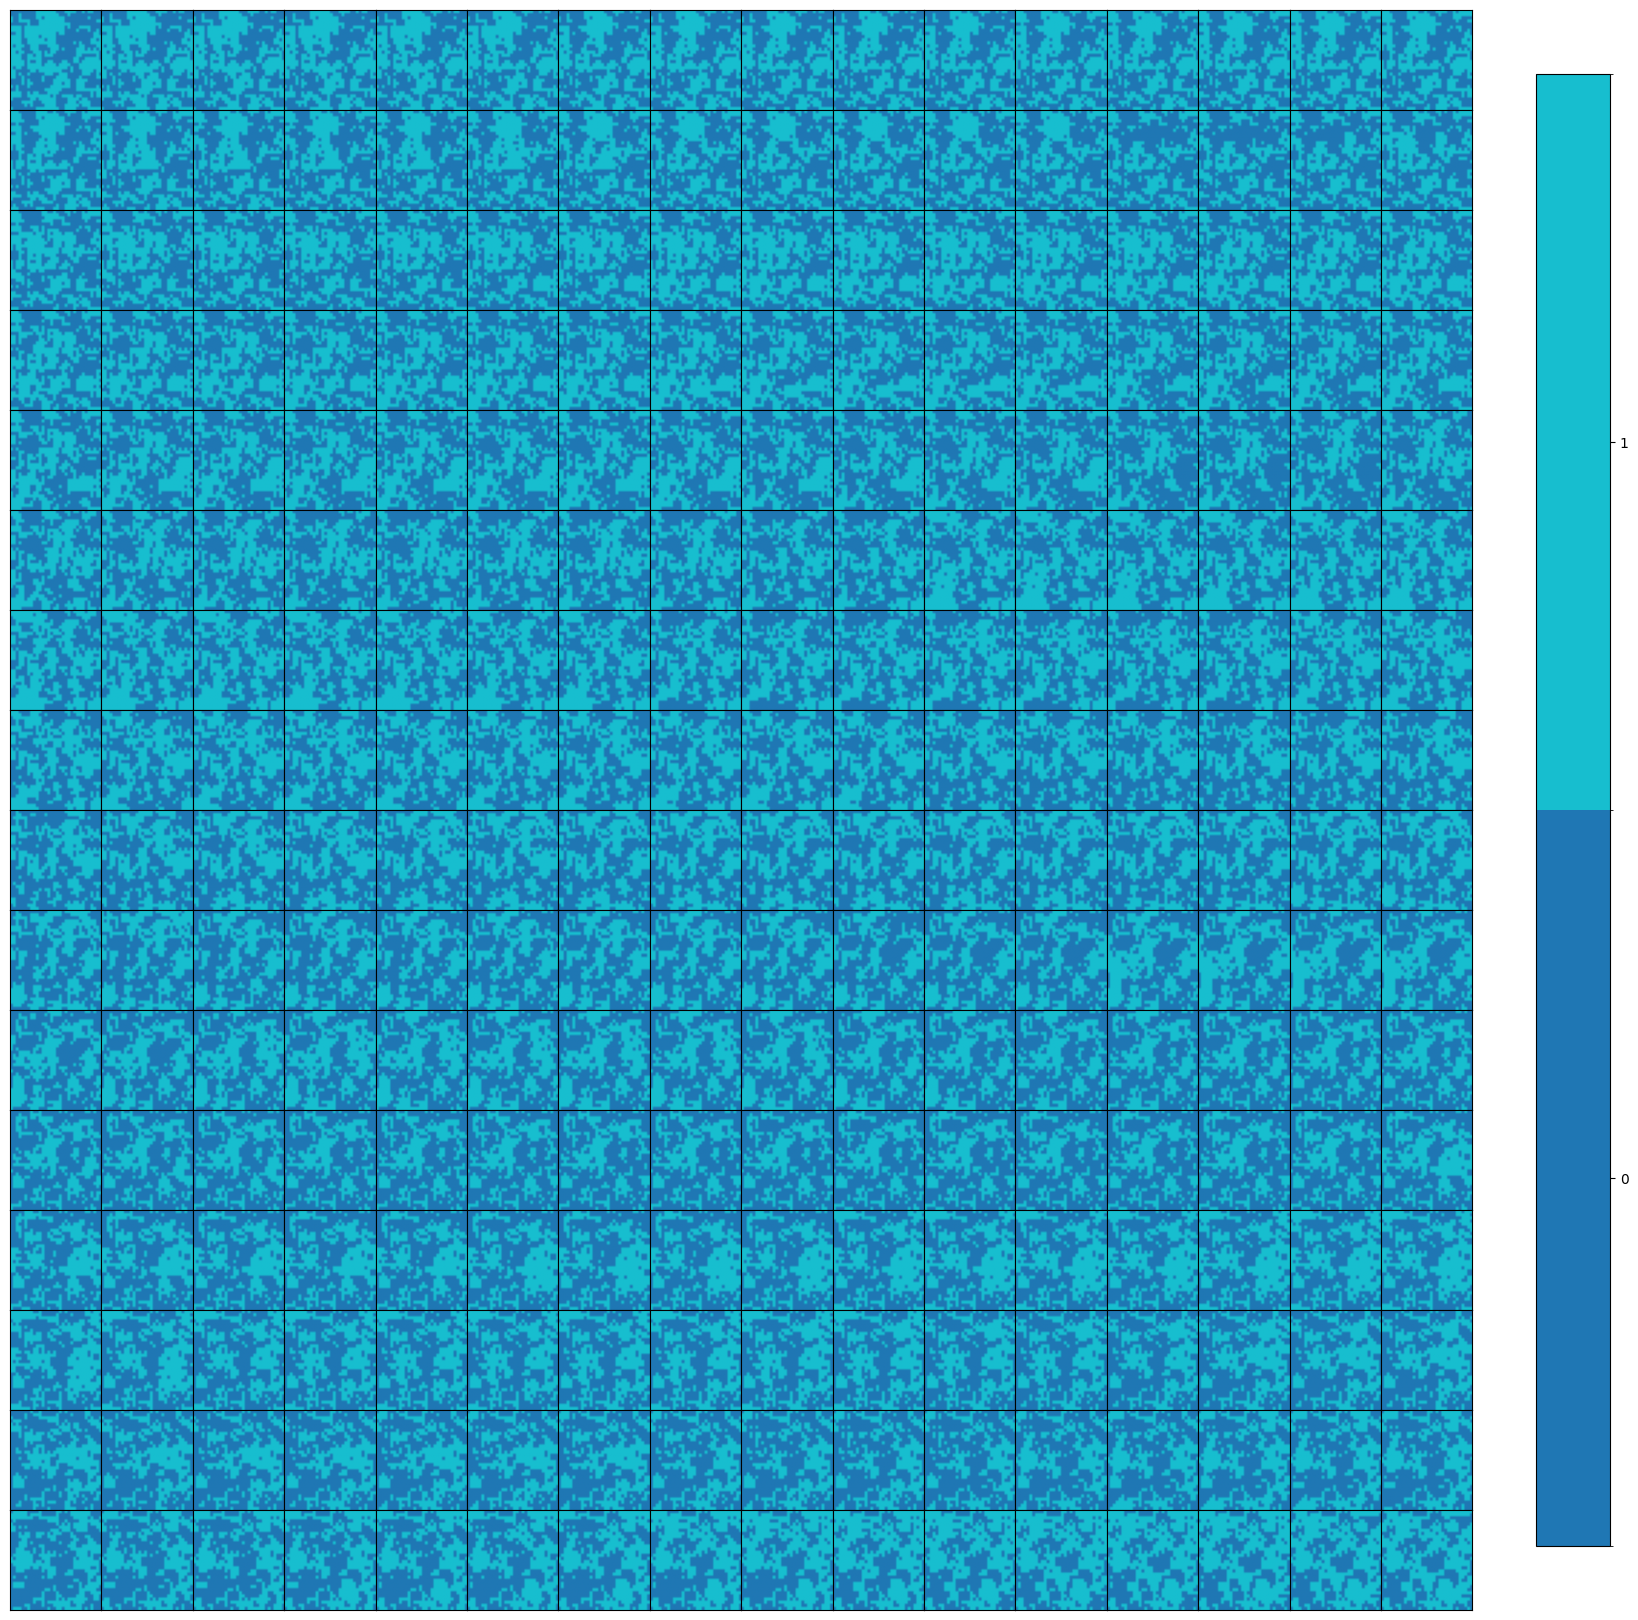

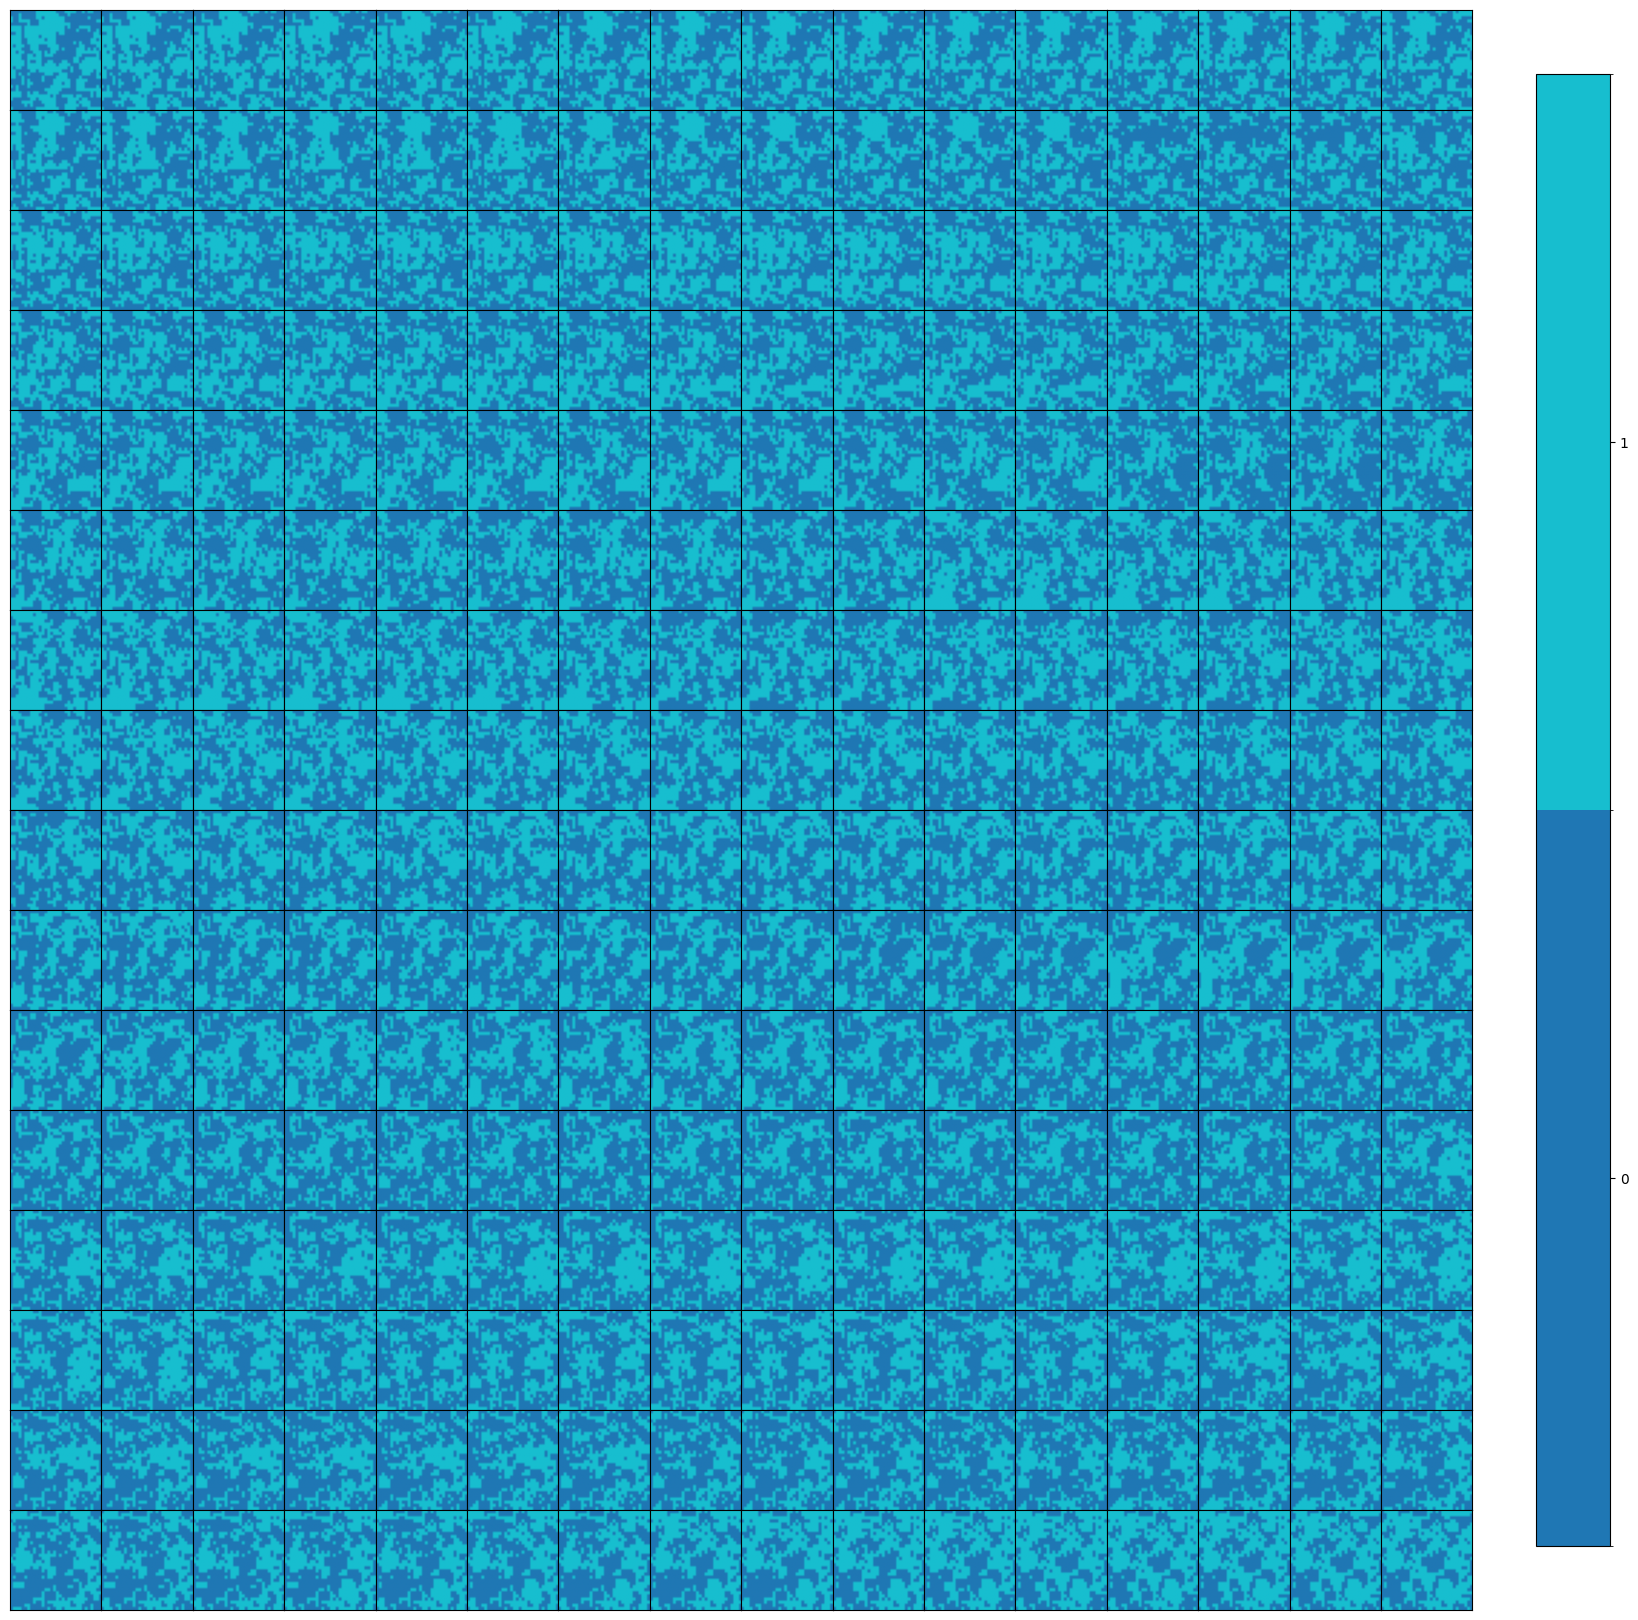

In [5]:
L=32
q = 2
T = 1.5

data_dir = "/home/sorasakai/PythonProjects/rbm-review-pc/rbm-review/data"
path = os.path.join(
    data_dir, f"2dPotts_L{L}", f"potts_configs_q{q}L{L}T{T:.3f}.npy"
)

dataset=np.load(path)

start = np.random.randint(0, len(dataset)-256)
sample = dataset[start:start + 256]
tensor = torch.from_numpy(sample)

plot_grid_of_images(tensor, range(256), 16, 16, (32, 32), 2, cmap="tab10", save=False)

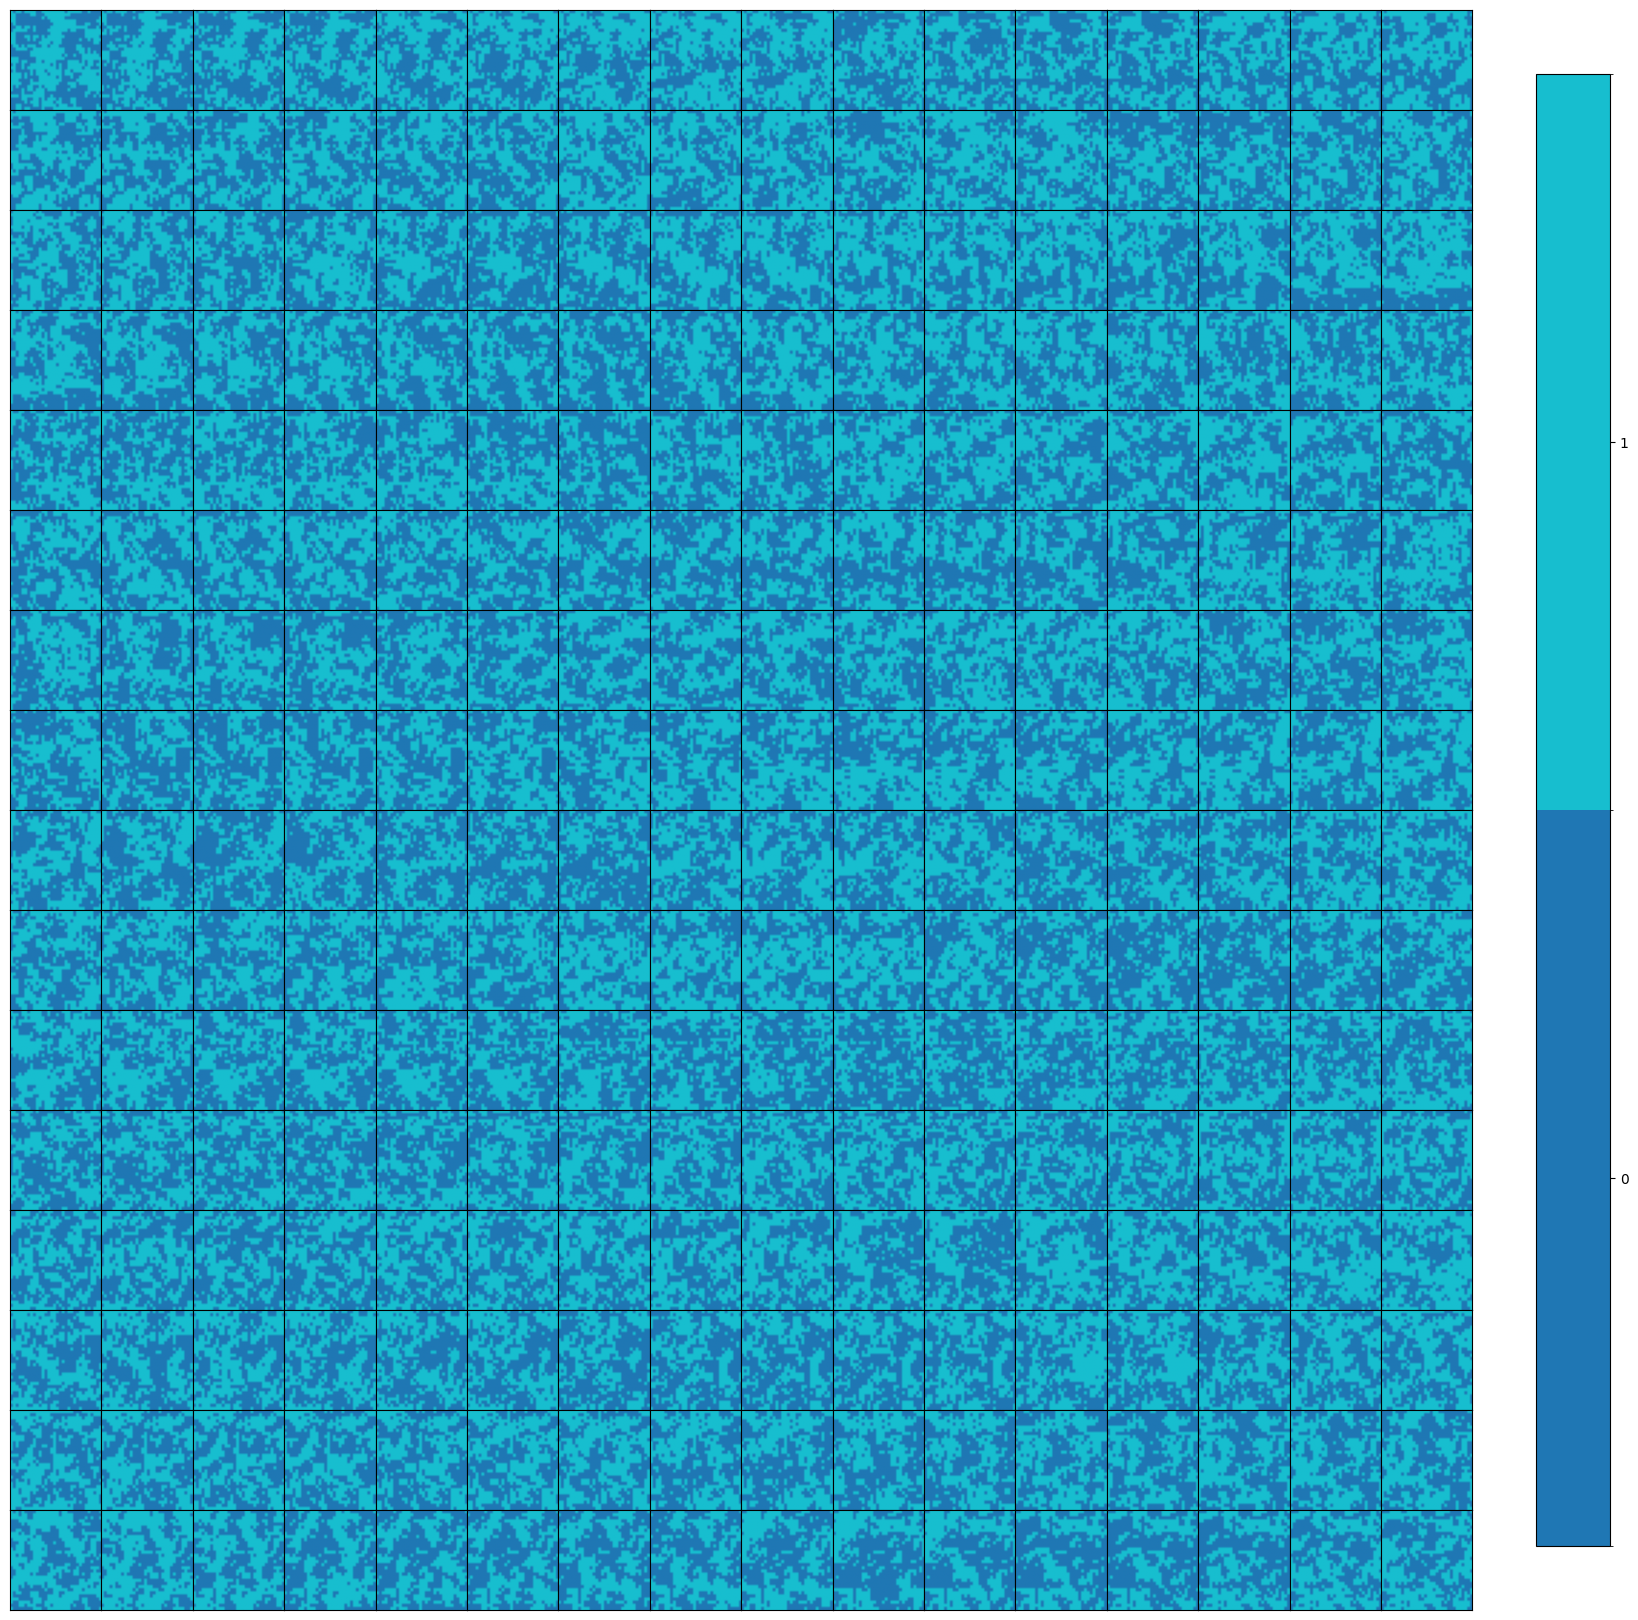

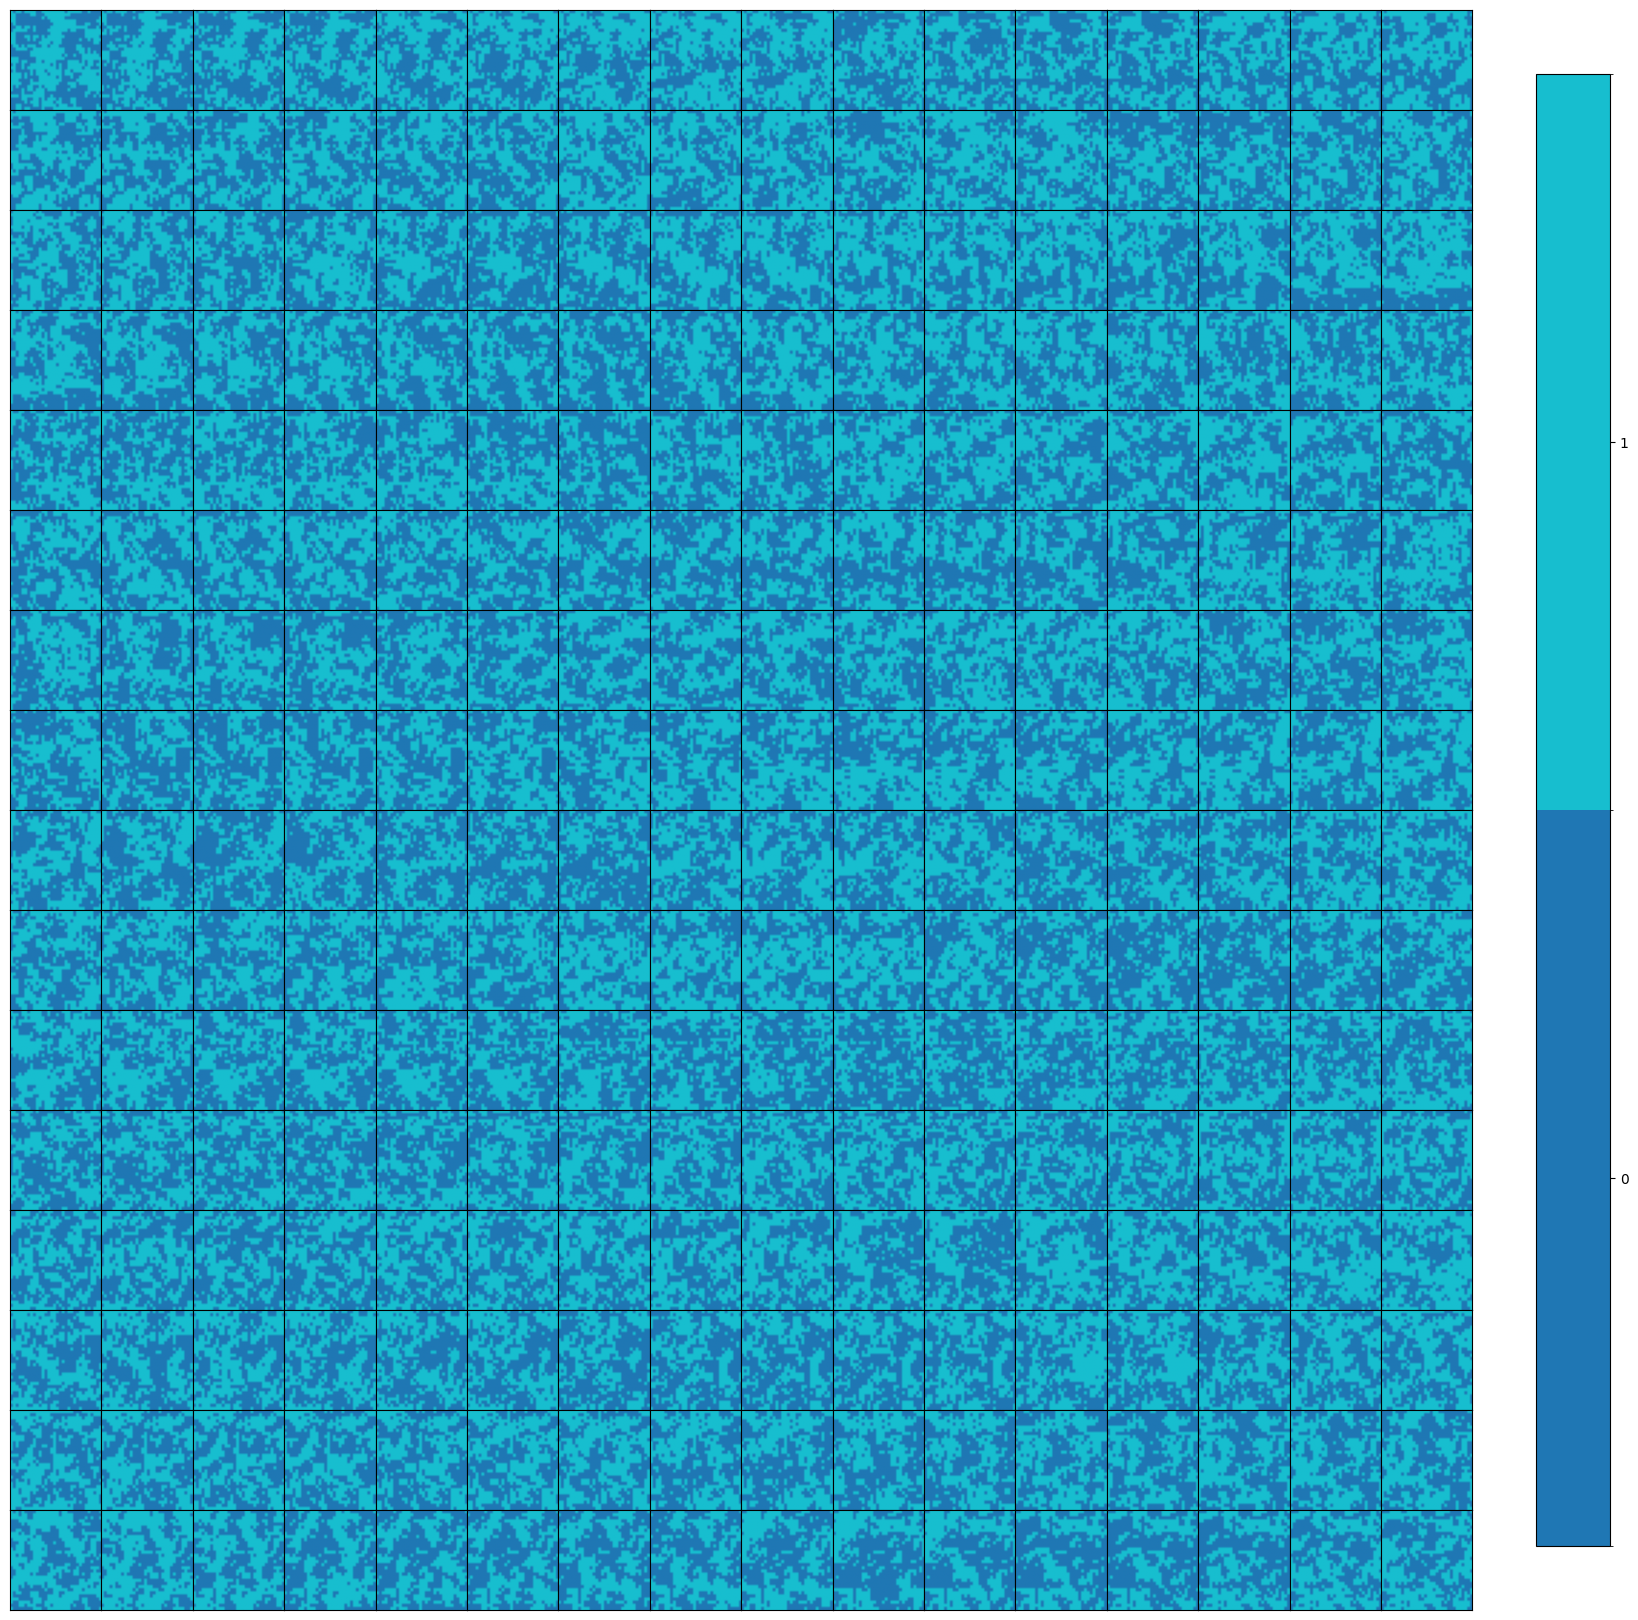

In [8]:
L=32
q = 2
T = 1.5

data_dir = "/home/sorasakai/PythonProjects/rbm-review-pc/rbm-review/data"
path = os.path.join(
    data_dir, f"2dPotts_L{L}_10", f"potts_configs_q{q}L{L}T{T:.3f}.npy"
)

dataset=np.load(path)

start = np.random.randint(0, len(dataset)-256)
sample = dataset[start:start + 256]
tensor = torch.from_numpy(sample)

plot_grid_of_images(tensor, range(256), 16, 16, (32, 32), 2, cmap="tab10", save=False)